# NPDES Outfall Data Exploration

This notebook explores the supplied EPA NPDES outfall CSV and identifies records located within the project’s NHDPlus Great Lakes catchments. It checks the file schema, coordinate coverage, permit summaries, and mapped locations.

The source CSV is national and large, so it is read in chunks. Great Lakes records are selected by testing each coordinate against the actual catchment polygons. Points outside those polygons, including possible direct-to-lake locations, are not included in that subset. Raw inputs are read-only.

In [3]:
# Load the libraries used to inspect permit records and locations.

from collections import Counter
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
# Locate the NPDES CSV and Great Lakes catchments, then inspect the CSV fields.

npdes_candidates = [
    Path("../data/raw/npdes/npdes_outfalls_layer.csv"),
    Path("data/raw/npdes/npdes_outfalls_layer.csv"),
]
outfalls_path = next((path.resolve() for path in npdes_candidates if path.is_file()), None)
if outfalls_path is None:
    searched = ", ".join(str(path.resolve()) for path in npdes_candidates)
    raise FileNotFoundError(f"NPDES CSV not found. Searched: {searched}")

catchment_relative_path = Path(
    "NHDPlusCatchments/NHDPlus04/NHDPlusCatchment/Catchment.shp"
)
catchment_candidates = [
    Path("../data/raw/nhdplus") / catchment_relative_path,
    Path("data/raw/nhdplus") / catchment_relative_path,
]
catchment_path = next(
    (path.resolve() for path in catchment_candidates if path.is_file()),
    None,
)
if catchment_path is None:
    searched = ", ".join(str(path.resolve()) for path in catchment_candidates)
    raise FileNotFoundError(f"NHDPlus catchments not found. Searched: {searched}")

columns = pd.read_csv(outfalls_path, nrows=0).columns.tolist()
required_columns = [
    "EXTERNAL_PERMIT_NMBR",
    "FACILITY_NAME",
    "STATE_CODE",
    "PERMIT_TYPE_CODE",
    "PERMIT_TYPE_DESC",
    "PERMIT_STATUS_CODE",
    "PERMIT_STATUS_DESC",
    "MAJOR_MINOR_FLAG",
    "TOTAL_DESIGN_FLOW_NMBR",
    "LATITUDE83",
    "LONGITUDE83",
    "LATLONG_TYPE",
]
missing_columns = sorted(set(required_columns) - set(columns))
if missing_columns:
    raise ValueError(f"NPDES CSV is missing expected columns: {missing_columns}")

print("NPDES CSV:", outfalls_path)
print(f"File size: {outfalls_path.stat().st_size / 1_000_000:.1f} MB")
print("Columns:", len(columns))
print("NHDPlus catchments:", catchment_path)

catchments = gpd.read_file(catchment_path, columns=[])
if catchments.crs is None:
    raise ValueError("NHDPlus catchment layer has no CRS")
catchment_bounds = catchments.total_bounds
print(f"Catchment polygons: {len(catchments):,}")
print("Catchment CRS:", catchments.crs)
print("Catchment bounds:", catchment_bounds)

preview_columns = [
    "EXTERNAL_PERMIT_NMBR",
    "FACILITY_NAME",
    "STATE_CODE",
    "PERMIT_STATUS_DESC",
    "PERMIT_TYPE_DESC",
    "LATITUDE83",
    "LONGITUDE83",
]
display(pd.read_csv(outfalls_path, usecols=preview_columns, nrows=6))

NPDES CSV: /home/rasheedr/graph-based-water-quality/data/raw/npdes/npdes_outfalls_layer.csv
File size: 318.7 MB
Columns: 39
NHDPlus catchments: /home/rasheedr/graph-based-water-quality/data/raw/nhdplus/NHDPlusCatchments/NHDPlus04/NHDPlusCatchment/Catchment.shp
Catchment polygons: 105,849
Catchment CRS: EPSG:4269
Catchment bounds: [-93.2137198   40.39475357 -73.64593551  48.29820403]


,EXTERNAL_PERMIT_NMBR,FACILITY_NAME,STATE_CODE,PERMIT_TYPE_DESC,PERMIT_STATUS_DESC,LATITUDE83,LONGITUDE83
0,01R10I004,DR. CHILDS ROAD RECONSTRUCTION,NH,General Permit Covered Facility,Terminated,43.6079,-71.6483
1,01R10I007,BEST FORD NASHUA,NH,General Permit Covered Facility,Effective,42.8008,-71.5358
2,01R10I008,LITTLE BAY ROAD WATER IMPROVEMENTS,NH,General Permit Covered Facility,Terminated,43.1082,-70.8483
3,01R10I009,BENEVENTO - CONCRETE BATCH PLANT,NH,General Permit Covered Facility,Effective,43.3262,-71.4715
4,01R10I00A,TOWN OF HANOVER WATER DISTRIBUTION IMPROVEMENTS,NH,General Permit Covered Facility,Effective,43.7002,-72.2959
5,01R10I00I,89 & 91 PORTSMOUTH AVENUE,NH,General Permit Covered Facility,Effective,43.0139,-70.9178


In [6]:
# Stream through the national CSV and keep only points inside Great Lakes catchments.

selected_columns = [
    "EXTERNAL_PERMIT_NMBR",
    "FACILITY_NAME",
    "STATE_CODE",
    "FAC_COUNTY_NAME",
    "PERMIT_TYPE_CODE",
    "PERMIT_TYPE_DESC",
    "PERMIT_STATUS_CODE",
    "PERMIT_STATUS_DESC",
    "MAJOR_MINOR_FLAG",
    "TOTAL_DESIGN_FLOW_NMBR",
    "LATITUDE83",
    "LONGITUDE83",
    "LATLONG_TYPE",
]

left, bottom, right, top = catchment_bounds
record_count = 0
valid_coordinate_count = 0
missing_coordinate_count = 0
invalid_coordinate_count = 0
bounding_box_candidate_count = 0
in_catchment_count = 0
missing_counts = Counter()
state_counts = Counter()
status_counts = Counter()
type_counts = Counter()
major_minor_counts = Counter()
regional_chunks = []

for chunk in pd.read_csv(
    outfalls_path,
    usecols=selected_columns,
    chunksize=100_000,
    low_memory=False,
):
    record_count += len(chunk)
    missing_counts.update(chunk[selected_columns].isna().sum().to_dict())

    latitude = pd.to_numeric(chunk["LATITUDE83"], errors="coerce")
    longitude = pd.to_numeric(chunk["LONGITUDE83"], errors="coerce")
    missing_coordinates = latitude.isna() | longitude.isna()
    valid_coordinates = (
        latitude.between(-90, 90) & longitude.between(-180, 180)
    )
    missing_coordinate_count += int(missing_coordinates.sum())
    invalid_coordinate_count += int((~missing_coordinates & ~valid_coordinates).sum())
    valid_coordinate_count += int(valid_coordinates.sum())

    in_bounds = (
        valid_coordinates
        & latitude.between(bottom, top)
        & longitude.between(left, right)
    )
    candidates = chunk.loc[in_bounds].copy()
    bounding_box_candidate_count += len(candidates)
    if candidates.empty:
        continue

    points = gpd.GeoDataFrame(
        candidates,
        geometry=gpd.points_from_xy(
            candidates["LONGITUDE83"],
            candidates["LATITUDE83"],
        ),
        crs=catchments.crs,
    )
    matched = gpd.sjoin(
        points,
        catchments[["geometry"]],
        how="inner",
        predicate="within",
    ).drop(columns="index_right", errors="ignore")
    in_catchment_count += len(matched)
    if matched.empty:
        continue

    regional_chunks.append(matched)
    for counter, column in [
        (state_counts, "STATE_CODE"),
        (status_counts, "PERMIT_STATUS_DESC"),
        (type_counts, "PERMIT_TYPE_DESC"),
        (major_minor_counts, "MAJOR_MINOR_FLAG"),
    ]:
        counter.update(
            matched[column].fillna("Missing").astype(str).value_counts().to_dict()
        )

if not regional_chunks:
    raise ValueError("No NPDES records were matched to the NHDPlus catchments")

regional_outfalls = gpd.GeoDataFrame(
    pd.concat(regional_chunks, ignore_index=True),
    geometry="geometry",
    crs=catchments.crs,
)

coverage_summary = pd.DataFrame(
    {
        "Measure": [
            "National NPDES records",
            "Records with valid coordinates",
            "Records with missing coordinates",
            "Records with invalid coordinates",
            "Records inside catchment bounding box",
            "Records inside catchment polygons",
        ],
        "Count": [
            record_count,
            valid_coordinate_count,
            missing_coordinate_count,
            invalid_coordinate_count,
            bounding_box_candidate_count,
            in_catchment_count,
        ],
    }
)
display(coverage_summary)
print(f"Great Lakes matched records retained for exploration: {len(regional_outfalls):,}")

,Measure,Count
0,National NPDES records,830019
1,Records with valid coordinates,830019
2,Records with missing coordinates,0
3,Records with invalid coordinates,0
4,Records inside catchment bounding box,64861
5,Records inside catchment polygons,17192


Great Lakes matched records retained for exploration: 17,192


NPDES records by state within catchments:


,State,Records
0,NY,4218
1,IN,3961
2,MI,3464
3,WI,2278
4,OH,2256
5,PA,699
6,MN,223
7,IL,91
8,ND,2


Permit status within catchments:


,Permit status,Records
0,Effective,9116
1,Admin Continued,3782
2,Terminated,2889
3,Expired,1302
4,Missing,65
5,Not Needed,35
6,Pending,3


Permit type within catchments:


...

,Classification,Records
0,Minor,14782
1,Major,2410


Missing values in inspected national columns:


,Column,Missing records
9,TOTAL_DESIGN_FLOW_NMBR,652072
3,FAC_COUNTY_NAME,55211
6,PERMIT_STATUS_CODE,8001
7,PERMIT_STATUS_DESC,8001
1,FACILITY_NAME,2
4,PERMIT_TYPE_CODE,0
2,STATE_CODE,0
0,EXTERNAL_PERMIT_NMBR,0
5,PERMIT_TYPE_DESC,0
8,MAJOR_MINOR_FLAG,0


Design-flow field summary for matched records:


,TOTAL_DESIGN_FLOW_NMBR
count,3493.000000
mean,23.577024
std,66.805762
min,0.000000
25%,0.015000
50%,0.400000
75%,8.000000
max,684.880000


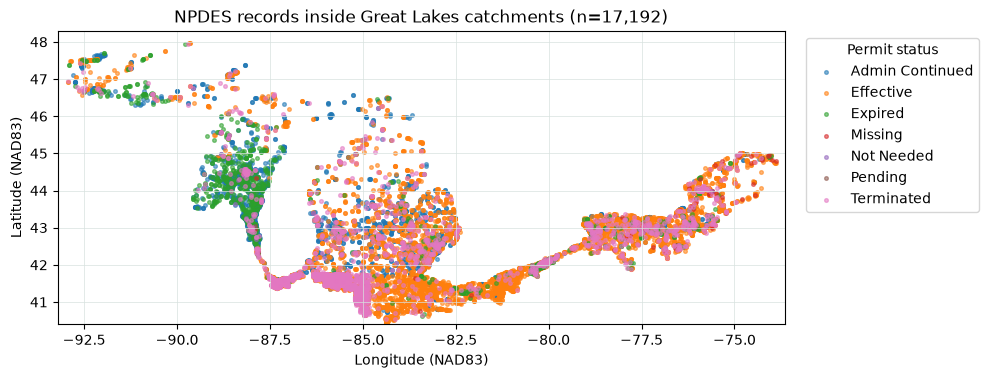

,EXTERNAL_PERMIT_NMBR,FACILITY_NAME,STATE_CODE,PERMIT_STATUS_DESC,PERMIT_TYPE_DESC,MAJOR_MINOR_FLAG,LATITUDE83,LONGITUDE83
0,IL0001881,ABBVIE INC NORTH CHICAGO FACILITY,IL,Admin Continued,NPDES Individual Permit,Major,42.328056,-87.831667
1,IL0001881,ABBVIE INC NORTH CHICAGO FACILITY,IL,Admin Continued,NPDES Individual Permit,Major,42.343333,-87.826389
2,IL0002259,"MIDWEST GENERATION, LLC",IL,Effective,NPDES Individual Permit,Major,42.383333,-87.808611
3,IL0002364,WINNETKA POWER GENERATION STATION,IL,Effective,NPDES Individual Permit,Minor,42.116111,-87.729722
4,IL0002364,WINNETKA POWER GENERATION STATION,IL,Effective,NPDES Individual Permit,Minor,42.115972,-87.729861
5,IL0002640,PVS CHEMICAL SOLUTIONS INC,IL,Effective,NPDES Individual Permit,Minor,41.672222,-87.552500
6,IL0002640,PVS CHEMICAL SOLUTIONS INC,IL,Effective,NPDES Individual Permit,Minor,41.672222,-87.552500
7,IL0026531,ILLINOIS CENTER - ONE BUILDING,IL,Effective,NPDES Individual Permit,Minor,41.891667,-87.625000
8,IL0026808,"ST. CHARLES WESTSIDE WWTF, CITY OF",IL,Effective,NPDES Individual Permit,Minor,42.895833,-82.375000
9,IL0028061,MWRDGC CALUMET WRP,IL,Admin Continued,NPDES Individual Permit,Major,41.673889,-87.551667


In [8]:
# Summarize the matched Great Lakes records and map them by permit status.

def counter_table(counter, label):
    return pd.DataFrame(counter.most_common(), columns=[label, "Records"])


print("NPDES records by state within catchments:")
display(counter_table(state_counts, "State"))

print("Permit status within catchments:")
display(counter_table(status_counts, "Permit status"))

print("Permit type within catchments:")
display(counter_table(type_counts, "Permit type").head(10))

print("Major/minor classification within catchments:")
display(counter_table(major_minor_counts, "Classification"))

missing_summary = pd.DataFrame(
    {
        "Column": selected_columns,
        "Missing records": [missing_counts[column] for column in selected_columns],
    }
).sort_values("Missing records", ascending=False)
print("Missing values in inspected national columns:")
display(missing_summary)

print("Design-flow field summary for matched records:")
design_flow = pd.to_numeric(
    regional_outfalls["TOTAL_DESIGN_FLOW_NMBR"],
    errors="coerce",
).dropna()
display(design_flow.describe().to_frame("TOTAL_DESIGN_FLOW_NMBR"))

regional_outfalls["STATUS_FOR_MAP"] = (
    regional_outfalls["PERMIT_STATUS_DESC"].fillna("Missing").astype(str)
)
status_order = sorted(regional_outfalls["STATUS_FOR_MAP"].unique())
status_colors = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(10, 7))
for index, status in enumerate(status_order):
    points = regional_outfalls.loc[
        regional_outfalls["STATUS_FOR_MAP"] == status
    ]
    ax.scatter(
        points.geometry.x,
        points.geometry.y,
        s=7,
        alpha=0.55,
        color=status_colors(index % 10),
        label=status,
        rasterized=True,
    )

ax.set_xlim(left, right)
ax.set_ylim(bottom, top)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Longitude (NAD83)")
ax.set_ylabel("Latitude (NAD83)")
ax.set_title(f"NPDES records inside Great Lakes catchments (n={len(regional_outfalls):,})")
ax.grid(color="#d8e1df", linewidth=0.5)
ax.legend(title="Permit status", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(
    regional_outfalls[
        [
            "EXTERNAL_PERMIT_NMBR",
            "FACILITY_NAME",
            "STATE_CODE",
            "PERMIT_STATUS_DESC",
            "PERMIT_TYPE_DESC",
            "MAJOR_MINOR_FLAG",
            "LATITUDE83",
            "LONGITUDE83",
        ]
    ].head(10).drop(columns="geometry", errors="ignore")
)